In [100]:
!apt-get install unrar -y
!unrar x "/content/Concrete Crack Images for Classification.rar" /content/dataset/

Se truncaron las últimas líneas 5000 del resultado de transmisión.
Extracting  /content/dataset/Negative/15002.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15003.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15004.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15005.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15006.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15007.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15008.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15009.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15010.jpg                           88%  OK 
Extracting  /content/dataset/Negative/15011.jpg                           88%  OK 
Extracting  /

In [101]:
import os

a = os.listdir('/content/dataset/Positive')
b = os.listdir('/content/dataset/Negative')

print("Cantidad de fotos positivas:", len(a))
print("Cantidad de fotos negativas:", len(b))

Cantidad de fotos positivas: 20000
Cantidad de fotos negativas: 20000


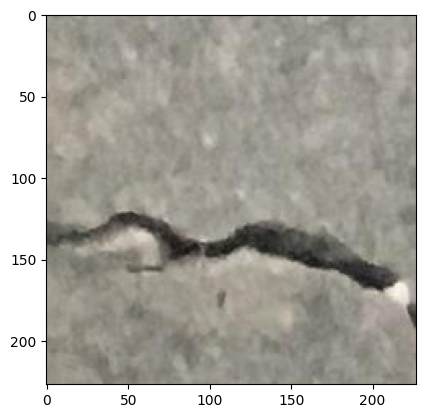

In [102]:
from PIL import Image
import matplotlib.pyplot as plt
foto = Image.open('/content/dataset/Positive/10512_1.jpg')
plt.imshow(foto)
plt.show()

In [ ]:
import tensorflow as tf

fotos1 = tf.keras.utils.image_dataset_from_directory('/content/dataset',validation_split=0.2,subset="training",seed=42,image_size=(227, 227),batch_size=32)
fotos2 = tf.keras.utils.image_dataset_from_directory('/content/dataset',validation_split=0.2,subset="validation",seed=42,image_size=(227, 227),batch_size=32)

capa1 = tf.keras.layers.Rescaling(1./255)
capa2 = tf.keras.layers.Conv2D(16, 3, activation='relu')
capa3 = tf.keras.layers.MaxPooling2D()
capa4 = tf.keras.layers.Flatten()
capa5 = tf.keras.layers.Dense(1, activation='sigmoid')

red = tf.keras.Sequential([capa1, capa2, capa3, capa4, capa5])

red.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

red.fit(fotos1, validation_data=fotos2, epochs=5)

Found 40000 files belonging to 2 classes.
Using 32000 files for training.
Found 40000 files belonging to 2 classes.
Using 8000 files for validation.
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 738s 736ms/step - accuracy: 0.9366 - loss: 0.2048 - val_accuracy: 0.9786 - val_loss: 0.1076


In [104]:
red.save('modelo_base_grietas.keras')

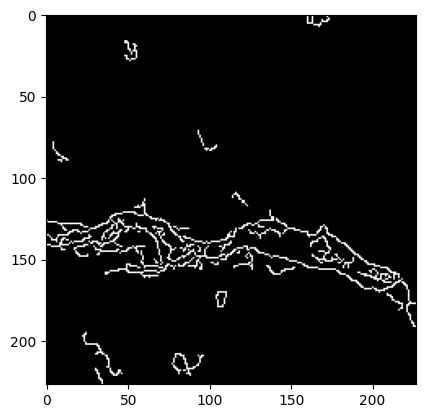

In [105]:
import cv2
import matplotlib.pyplot as plt

foto = cv2.imread('/content/dataset/Positive/10512_1.jpg')
gris = cv2.cvtColor(foto, cv2.COLOR_BGR2GRAY)
bordes = cv2.Canny(gris, 50, 150)

plt.imshow(bordes, cmap='gray')
plt.show()

In [106]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

foto = cv2.imread('/content/dataset/Positive/10512_1.jpg')
gris = cv2.cvtColor(foto, cv2.COLOR_BGR2GRAY)
bordes = cv2.Canny(gris, 50, 150)

lineas = cv2.HoughLinesP(bordes, 1, np.pi/180, 100, minLineLength=50, maxLineGap=10)
angulos = []

if lineas is None: lineas = []
for l in lineas: x1 = l[0][0]; y1 = l[0][1]; x2 = l[0][2]; y2 = l[0][3]; dx = abs(x2 - x1); dy = abs(y2 - y1); rad = np.arctan2(dx, dy); grad = np.degrees(rad); angulos.append(grad)

if len(angulos) > 0: inclinacion = np.mean(angulos)
else: inclinacion = 0.0

print("Inclinación estimada en grados:", inclinacion)

Inclinación estimada en grados: 0.0


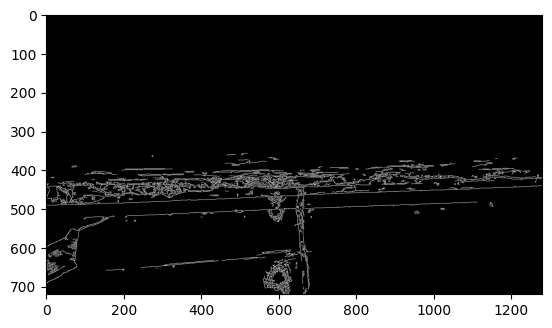

Inclinación estimada en grados: 87.10194767228225


In [107]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

foto = cv2.imread('/content/mi_foto.jpg')
gris = cv2.cvtColor(foto, cv2.COLOR_BGR2GRAY)
bordes = cv2.Canny(gris, 50, 150)
plt.imshow(bordes, cmap='gray'); plt.show()

lineas = cv2.HoughLinesP(bordes, 1, np.pi/180, 100, minLineLength=50, maxLineGap=10)
angulos = []

if lineas is not None:
  for l in lineas: x1, y1, x2, y2 = np.array(l).ravel(); dx = abs(x2 - x1); dy = abs(y2 - y1); rad = np.arctan2(dx, dy); grad = np.degrees(rad); angulos.append(grad)

if len(angulos) > 0: inclinacion = np.mean(angulos)
else: inclinacion = 0.0

print("Inclinación estimada en grados:", inclinacion)

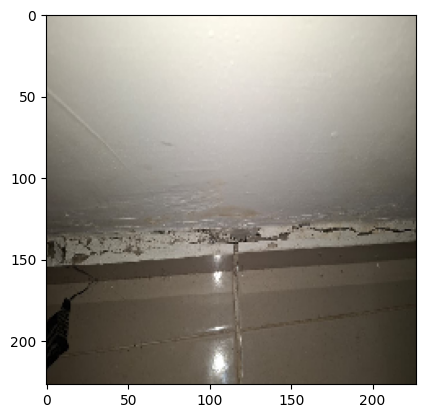

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
Resultado: Se detectó grieta
Nivel de Riesgo: ALTO


In [108]:
import tensorflow as tf
import matplotlib.pyplot as plt

foto = tf.keras.utils.load_img('/content/mi_foto.jpg', target_size=(227, 227))
plt.imshow(foto)
plt.show()

matriz = tf.keras.utils.img_to_array(foto)
matriz = tf.expand_dims(matriz, 0)

prediccion = red.predict(matriz)
probabilidad = prediccion[0][0]

if probabilidad > 0.5: tiene_grieta = True; print("Resultado: Se detectó grieta")
else: tiene_grieta = False; print("Resultado: No se detectó grieta")

if tiene_grieta and inclinacion > 3.0: print("Nivel de Riesgo: ALTO")
elif tiene_grieta or inclinacion > 1.5: print("Nivel de Riesgo: MEDIO")
else: print("Nivel de Riesgo: BAJO")